In [1]:
import sys
print(sys.executable)

/Users/aminentezari/Desktop/Projects_python/olist-customer-analytics/.venv/bin/python


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

engine = create_engine("postgresql+psycopg2://localhost/olist")
sns.set_theme(style="whitegrid")

In [3]:
query = """
SELECT c.customer_unique_id,
       MAX(f.order_date)  AS last_order_date,
       COUNT(*)           AS frequency,
       SUM(f.revenue)     AS monetary
FROM fact_orders f
JOIN dim_customer c ON c.customer_id = f.customer_id
GROUP BY c.customer_unique_id
"""
rfm = pd.read_sql(query, engine)
rfm["last_order_date"] = pd.to_datetime(rfm["last_order_date"])

snapshot = pd.Timestamp("2018-09-01")   # day after the analysis window
rfm["recency"] = (snapshot - rfm["last_order_date"]).dt.days

print(rfm.shape)
rfm[["recency", "frequency", "monetary"]].describe().round(2)

(93104, 5)


,recency,frequency,monetary
count,93104.00,93104.00,93104.00
mean,239.24,1.03,141.57
std,150.95,0.21,215.76
min,3.00,1.00,0.85
25%,117.00,1.00,47.65
50%,221.00,1.00,89.70
75%,348.00,1.00,154.17
max,604.00,15.00,13440.00


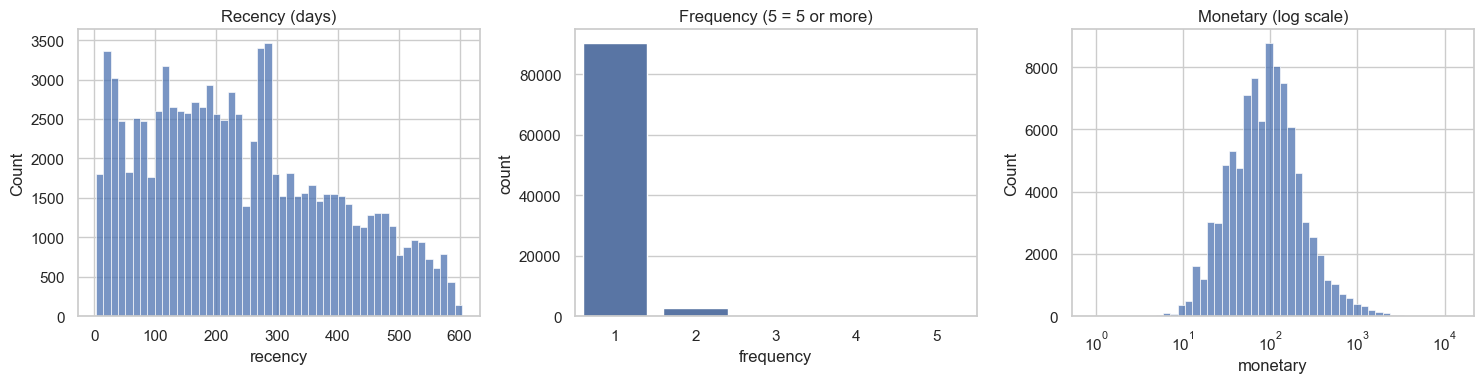

frequency
1    0.9700
2    0.0275
3    0.0019
4    0.0003
5    0.0001
Name: proportion, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rfm["recency"], bins=50, ax=axes[0]); axes[0].set_title("Recency (days)")
sns.countplot(x=rfm["frequency"].clip(upper=5), ax=axes[1]); axes[1].set_title("Frequency (5 = 5 or more)")
sns.histplot(rfm["monetary"], bins=50, log_scale=True, ax=axes[2]); axes[2].set_title("Monetary (log scale)")
plt.tight_layout(); plt.show()

print(rfm["frequency"].value_counts(normalize=True).head().round(4))

In [5]:
X = pd.DataFrame({
    "recency": rfm["recency"],
    "log_monetary": np.log1p(rfm["monetary"]),
    "is_repeat": (rfm["frequency"] >= 2).astype(int),
})
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)
X.describe().round(2)

(93104, 3)


,recency,log_monetary,is_repeat
count,93104.00,93104.00,93104.00
mean,239.24,4.49,0.03
std,150.95,0.92,0.17
min,3.00,0.62,0.00
25%,117.00,3.88,0.00
50%,221.00,4.51,0.00
75%,348.00,5.04,0.00
max,604.00,9.51,1.00


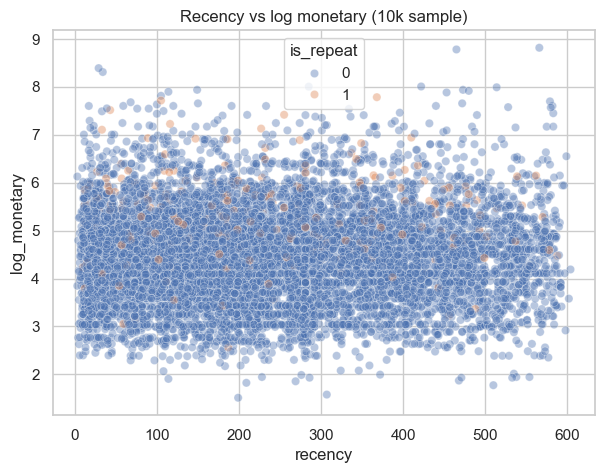

In [6]:
sample = X.sample(10000, random_state=42)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=sample, x="recency", y="log_monetary", hue="is_repeat", alpha=0.4)
plt.title("Recency vs log monetary (10k sample)")
plt.show()

In [7]:
idx = np.random.RandomState(42).choice(len(X_scaled), 20000, replace=False)
Xs = X_scaled[idx]

rows = []
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)
    rows.append({"k": k,
                 "silhouette": silhouette_score(Xs, labels),
                 "davies_bouldin": davies_bouldin_score(Xs, labels),
                 "calinski_harabasz": calinski_harabasz_score(Xs, labels)})
kmeans_scores = pd.DataFrame(rows).round(3)
kmeans_scores

,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.717,0.407,10149.013
1,3,0.357,0.904,12985.384
2,4,0.366,0.769,16128.642
3,5,0.345,0.818,16388.915
4,6,0.343,0.855,16465.811
5,7,0.358,0.752,17096.288
6,8,0.351,0.799,16935.824


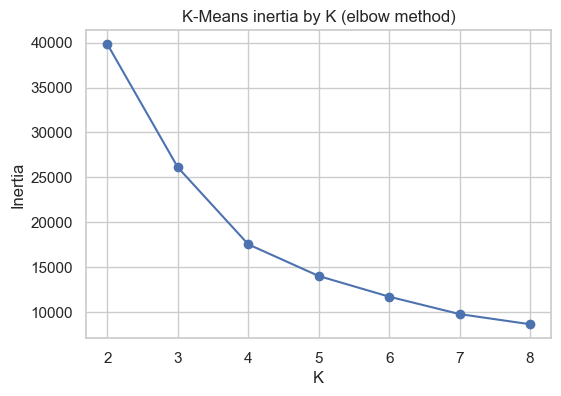

In [8]:
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs).inertia_ for k in range(2, 9)]
plt.figure(figsize=(6, 4))
plt.plot(range(2, 9), inertia, marker="o")
plt.title("K-Means inertia by K (elbow method)")
plt.xlabel("K"); plt.ylabel("Inertia")
plt.show()

In [9]:
results = []
for mcs in [200, 500, 1000]:
    hdb = HDBSCAN(min_cluster_size=mcs)
    labels = hdb.fit_predict(Xs)
    mask = labels != -1                     # -1 = noise, not a cluster
    n_clusters = len(set(labels[mask]))
    row = {"min_cluster_size": mcs,
           "n_clusters": n_clusters,
           "noise_pct": round(100 * (~mask).mean(), 1)}
    if n_clusters >= 2:
        row["silhouette"] = round(silhouette_score(Xs[mask], labels[mask]), 3)
        row["davies_bouldin"] = round(davies_bouldin_score(Xs[mask], labels[mask]), 3)
        row["calinski_harabasz"] = round(calinski_harabasz_score(Xs[mask], labels[mask]), 1)
    results.append(row)
pd.DataFrame(results)

,min_cluster_size,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz
0,200,2,0.0,0.717,0.407,10149.0
1,500,2,0.0,0.717,0.407,10149.0
2,1000,0,100.0,NaN,NaN,NaN


In [10]:
K = 4   # placeholder: change after we read the tables

final = KMeans(n_clusters=K, n_init=10, random_state=42)
rfm["cluster"] = final.fit_predict(X_scaled)

profile = (rfm.groupby("cluster")
              .agg(customers=("customer_unique_id", "count"),
                   recency_median=("recency", "median"),
                   monetary_median=("monetary", "median"),
                   monetary_total=("monetary", "sum"),
                   repeat_pct=("frequency", lambda s: round(100 * (s >= 2).mean(), 1))))
profile["pct_customers"] = (100 * profile["customers"] / profile["customers"].sum()).round(1)
profile["pct_revenue"] = (100 * profile["monetary_total"] / profile["monetary_total"].sum()).round(1)
profile.round(1)

,customers,recency_median,monetary_median,monetary_total,repeat_pct,pct_customers,pct_revenue
cluster,,,,,,,
0,2789,201.0,182.9,725355.0,100.0,3.0,5.5
1,32190,159.0,159.0,8090895.0,0.0,34.6,61.4
2,30751,157.0,43.2,1364239.0,0.0,33.0,10.4
3,27374,418.0,81.5,3000538.1,0.0,29.4,22.8


In [11]:
labels2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_scaled)
pd.crosstab(labels2, X["is_repeat"], rownames=["cluster"], colnames=["is_repeat"])

is_repeat,0,1
cluster,,
0,0,2789
1,90315,0


In [12]:
segment_names = {
    0: "Repeat customers",
    1: "High-value one-timers",
    2: "Low-value one-timers",
    3: "Lapsed customers",
}
rfm["segment"] = rfm["cluster"].map(segment_names)
rfm["segment"].value_counts()

segment
High-value one-timers    32190
Low-value one-timers     30751
Lapsed customers         27374
Repeat customers          2789
Name: count, dtype: int64

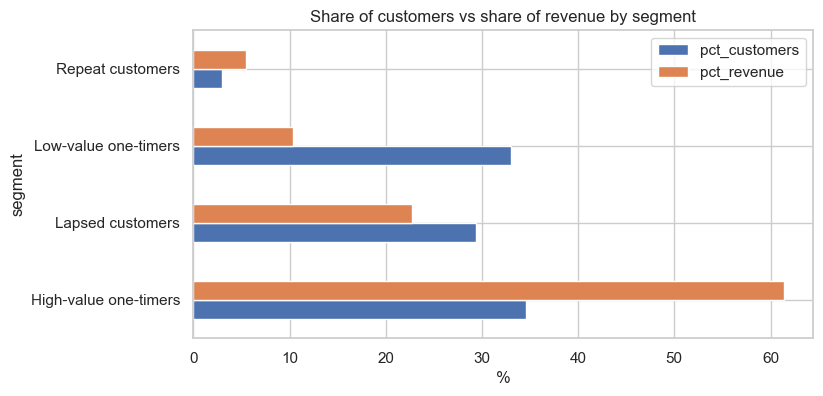

In [13]:
seg = (rfm.groupby("segment")
          .agg(customers=("customer_unique_id", "count"),
               revenue=("monetary", "sum")))
seg["pct_customers"] = 100 * seg["customers"] / seg["customers"].sum()
seg["pct_revenue"] = 100 * seg["revenue"] / seg["revenue"].sum()

seg[["pct_customers", "pct_revenue"]].plot(kind="barh", figsize=(8, 4))
plt.title("Share of customers vs share of revenue by segment")
plt.xlabel("%")
plt.show()

In [14]:
(rfm[["customer_unique_id", "segment", "recency", "frequency", "monetary"]]
    .to_sql("customer_segments", engine, if_exists="replace", index=False))

pd.read_sql("SELECT segment, COUNT(*) FROM customer_segments GROUP BY 1 ORDER BY 2 DESC", engine)

,segment,count
0,High-value one-timers,32190
1,Low-value one-timers,30751
2,Lapsed customers,27374
3,Repeat customers,2789
